Silakan unggah gambar Anda:


Saving 30cfbf92f75b434a4899155c7e5ae4e0.jpg to 30cfbf92f75b434a4899155c7e5ae4e0.jpg


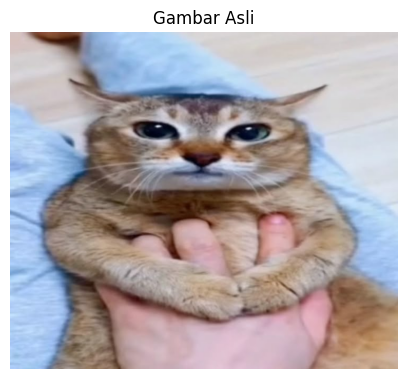

In [1]:
import numpy as np
import imageio.v3 as img
import matplotlib.pyplot as plt
from google.colab import files

# 1. Mengunggah gambar ke Google Colab
print("Silakan unggah gambar Anda:")
uploaded = files.upload()

# 2. Mengambil nama file gambar yang baru saja diunggah
filename = next(iter(uploaded))

# 3. Membaca gambar tersebut
image = img.imread(filename)

# Menampilkan gambar asli
plt.figure(figsize=(5, 5))
plt.title("Gambar Asli")
plt.imshow(image)
plt.axis('off')
plt.show()

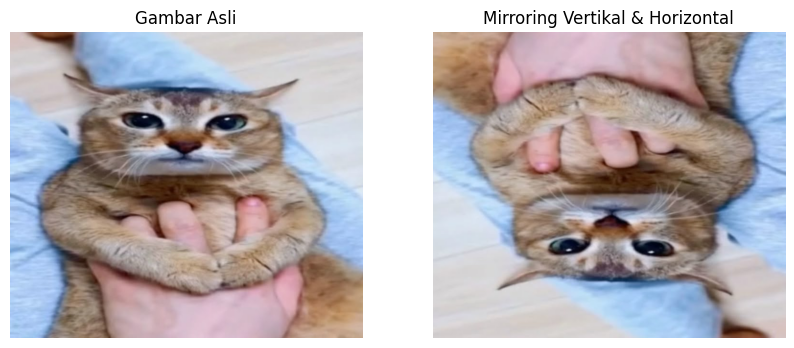

In [2]:
# Mengambil dimensi gambar
height, width = image.shape[:2]

# Buat array kosong dengan ukuran yang sama dengan gambar asli
both_mirror = np.zeros_like(image)

# Looping untuk memetakan piksel
for y in range(height):
    for x in range(width):
        # Membalik indeks baris (y) dan kolom (x) secara bersamaan
        both_mirror[y, x] = image[height - 1 - y, width - 1 - x]

# Menampilkan hasil
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Mirroring Vertikal & Horizontal")
plt.imshow(both_mirror)
plt.axis('off')
plt.show()

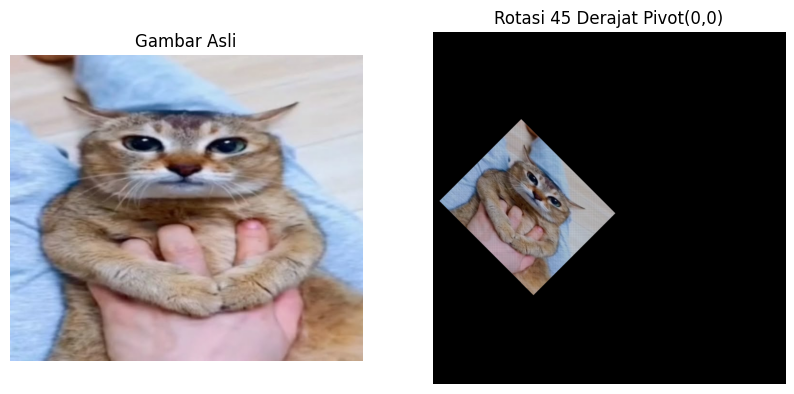

In [3]:
def rotateImagePivot00(img_input, degree):
    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    h, w = img_input.shape[:2]
    # Membuat ukuran kanvas output lebih besar agar gambar hasil putaran muat
    max_dim = int(np.sqrt(h**2 + w**2)) * 2
    outputImage = np.zeros((max_dim, max_dim, 3), dtype=img_input.dtype)

    # Offset agar saat diputar ke arah minus, gambar tidak keluar batas array
    offset_x, offset_y = max_dim // 4, max_dim // 4

    for y in range(h):
        for x in range(w):
            # Rotasi dengan pusat rotasi (0,0) dari gambar aslinya
            newX = int(cos_deg * x - sin_deg * y) + offset_x
            newY = int(sin_deg * x + cos_deg * y) + offset_y

            # Memastikan nilai piksel masih berada di dalam kanvas
            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = img_input[y, x]

    return outputImage

# Melakukan rotasi 45 derajat
rotated_image = rotateImagePivot00(image, 45)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Rotasi 45 Derajat Pivot(0,0)")
plt.imshow(rotated_image)
plt.axis('off')
plt.show()

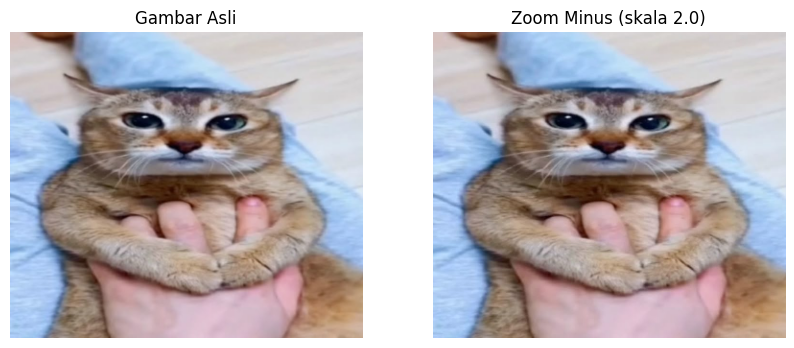

In [4]:
def zoomMinus(img_input, factor):
    h, w = img_input.shape[:2]

    # Dimensi kanvas baru dibagi dengan factor pengecilan
    new_height = int(h / factor)
    new_width = int(w / factor)
    imgZoomMinus = np.zeros((new_height, new_width, 3), dtype=img_input.dtype)

    for y in range(new_height):
        for x in range(new_width):
            # Mengalikan indeks baru dengan factor untuk mencari piksel asli
            ori_y = int(y * factor)
            ori_x = int(x * factor)

            # Membatasi indeks agar tidak melampaui batas matriks gambar asli
            ori_y = min(ori_y, h - 1)
            ori_x = min(ori_x, w - 1)

            imgZoomMinus[y, x] = img_input[ori_y, ori_x]

    return imgZoomMinus

# Mengecilkan gambar dengan skala 2.0 (menjadi setengahnya)
skala = 2.0
img_zoomed = zoomMinus(image, skala)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title(f"Zoom Minus (skala {skala})")
plt.imshow(img_zoomed)
plt.axis('off')
plt.show()